In [7]:
import numpy as np
from scipy.linalg import eigh
from scipy.integrate import solve_ivp
from scipy.constants import e, hbar, h

from transmon_func import transmon_hamiltonian, get_energy_levels

import matplotlib.pyplot as plt

In [8]:
# A gaussian envelope function, truncated at 5 sigma for optimization

def gaussian_envelope(t, t0, sigma):

    if abs(t-t0)<5*sigma:
        return np.exp( -(t-t0)**2 / (2*sigma**2) )
    else:
        return 0

# The transmon Hamiltonian with an addition of the drive microwave energy, now with a gaussian pulse envelope

def driven_hamiltonian(t, energies, n_energy,
                       EC, ng_ac, omega_d,
                       t0, sigma):

    H0 = np.diag(energies)

    A = gaussian_envelope(t, t0, sigma)

    H_drive = (
        -8 * EC * ng_ac
        * A * np.cos(omega_d * t)
        * n_energy
    )

    return H0 + H_drive

In [9]:
# The Schrodinger equation, now with a gaussian pulse hamiltonian

def schrodinger_equation(t, psi, energies,
                        n_energy, EC, ng_ac, omega_d,
                        t0, sigma):

    H = driven_hamiltonian(
        t, energies, n_energy,
        EC, ng_ac, omega_d,
        t0, sigma
    )

    return -1j / hbar * H @ psi

In [ ]:
# Choose a cutoff value for the charge states
N = 20

# Diagonalize the static Hamiltonian
C = 70e-15       # 70 fF
Ic = 40e-9       # 40 nA
EC = e**2 / (2*C)
EJ = hbar*Ic / (2*e)
H = transmon_hamiltonian(EJ, EC, N=N)

# Choose how many energy levels to include in the time-dependent equation
n_levels = 6
energies, n_energy = get_energy_levels(H, n_levels)

In [11]:
# Initializing the ground state
psi0 = np.zeros(n_levels, dtype=complex)
psi0[0] = 1

# Defining the driving frequency as the 01 transition frequency
# Solving the equation with a different driving frequency, we will clearly see a lack of popuation oscillations
omega_d = (energies[1] - energies[0]) / hbar

# Drive amplitude
# Should linearly affect the Rabi oscillations frequency
ng_ac = 0.003
rabi_freq = (8*EC*ng_ac)/hbar * abs(n_energy[0,1])

t_max = 500e-9

times = np.linspace(0, t_max, 2000)

# Envelope parameters for an overall pi pulse in the middle of the timeline
t0 = t_max/2
sigma = np.sqrt(np.pi)/(np.sqrt(2)*rabi_freq)

# Solving the time evolution
solution = solve_ivp(
    schrodinger_equation,
    (0, t_max),
    psi0,
    t_eval=times,
    args=(
        energies[:n_levels],
        n_energy,
        EC,
        ng_ac,
        omega_d,
        t0, sigma
    ),
    method="DOP853",
    max_step=1 / (40 * omega_d / (2*np.pi)),
    rtol=1e-8,
    atol=1e-10
)

states = solution.y.T

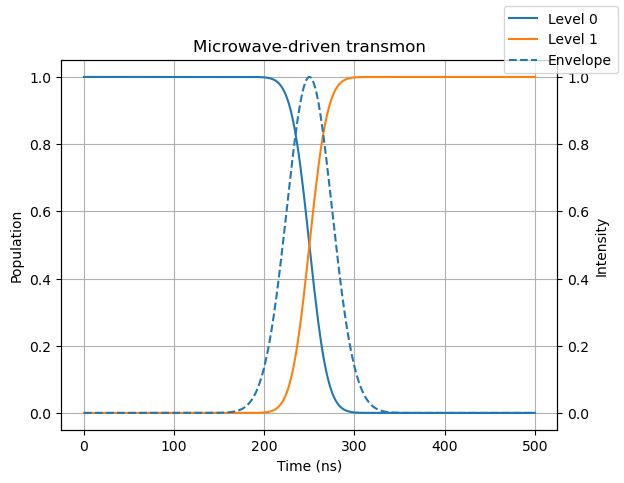

Final fidelity = 0.9998934393193901


In [12]:
# Plotting the populations in relation to time, with the pulse intensity overlayed

populations = np.abs(states)**2

fig, ax1 = plt.subplots()
for m in range(2):
    ax1.plot(
        times * 1e9,
        populations[:, m],
        label=f"Level {m}"
    )

envelope = np.exp( -(times-t0)**2 / (2*sigma**2) )
ax2 = ax1.twinx()
ax2.plot(times*1e9, envelope, "--", label="Envelope")
ax2.set_ylabel("Intensity")

ax1.set_xlabel("Time (ns)")
ax1.set_ylabel("Population")
ax1.set_title("Microwave-driven transmon")
fig.legend()
ax1.grid()
plt.show()

target_state = np.array([0, 1])
final_state = np.array([states[:,0][-1], states[:,1][-1]])
fidelity = (np.abs(np.vdot(target_state, final_state)))**2

print(f"Final fidelity = {fidelity}")

In [13]:
psi_final = solution.y[:, -1]

# Computational subspace populations
P0 = abs(psi_final[0])**2
P1 = abs(psi_final[1])**2

# Relative phase in the rotating frame
relative_phase = np.angle(
    psi_final[1] / psi_final[0]
    * np.exp(1j * omega_d * t_max)
)

# Leakage
leakage = 1 - P0 - P1

print("P0:", P0)
print("P1:", P1)
print("Relative phase, rotating frame:", relative_phase)
print("Final leakage:", leakage)

P0: 0.00010615158834028782
P1: 0.9998934393193899
Relative phase, rotating frame: 0.008554676631030553
Final leakage: 4.0909226983742997e-07
